<a href="https://colab.research.google.com/github/nabeeha-rafi/Pakistan-Social-Audience-Campaign-Intelligence-Engine/blob/main/campaign.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# DAY 1 MILESTONE: PAKISTANI LAWN BRAND SOCIAL DATA & PROVENANCE PIPELINE
# ==============================================================================

import numpy as np
import pandas as pd

def generate_pak_fashion_social_data(n_posts: int = 3000, seed: int = 42):
    """
    Prepares Table A (Social Media Posts) and Table B (Comments) for a Lahore-based
    women's lawn brand across Instagram, TikTok, and Facebook.
    """
    rng = np.random.default_rng(seed)

    brands = ["ZoyaLawn_Lahore", "Rangrez_PK", "SaffronThreads_LHR"]
    platforms = ["Instagram", "TikTok", "Facebook"]
    platform_probs = [0.46, 0.34, 0.20]

    campaigns = [
        "11.11_Mega_Sale",
        "12.12_Winter_Clearance",
        "Eid_Luxury_Lawn_2026",
        "Summer_Unstitched_Drop",
        "Flash_Weekend_Bundle",
    ]
    content_types = [
        "Reel",
        "Product Photo",
        "Influencer Post",
        "Styling Video",
        "Sale Announcement",
        "Eid Campaign",
    ]
    ct_probs = [0.26, 0.22, 0.16, 0.16, 0.12, 0.08]

    post_ids = [f"P{i:04d}" for i in range(1, n_posts + 1)]
    brand_arr = rng.choice(brands, size=n_posts)
    plat_arr = rng.choice(platforms, size=n_posts, p=platform_probs)
    camp_arr = rng.choice(campaigns, size=n_posts)
    ct_arr = rng.choice(content_types, size=n_posts, p=ct_probs)
    days_since = rng.integers(1, 90, size=n_posts)

    # Engagement multipliers by content format
    ct_view_mult = {
        "Reel": 2.4, "Styling Video": 1.9, "Influencer Post": 2.1,
        "Eid Campaign": 1.8, "Sale Announcement": 1.3, "Product Photo": 0.75
    }
    ct_like_mult = {
        "Reel": 1.7, "Styling Video": 1.4, "Influencer Post": 1.9,
        "Eid Campaign": 1.6, "Sale Announcement": 1.1, "Product Photo": 0.85
    }
    ct_comm_mult = {
        "Reel": 1.4, "Styling Video": 1.3, "Influencer Post": 1.5,
        "Eid Campaign": 1.3, "Sale Announcement": 2.1, "Product Photo": 1.0
    }

    base_views = np.where(plat_arr == "TikTok", 32000, np.where(plat_arr == "Instagram", 18000, 11000))
    views = np.maximum(800, (base_views * np.array([ct_view_mult[c] for c in ct_arr]) * rng.lognormal(0, 0.40, size=n_posts)).astype(int))
    likes = np.maximum(25, (views * 0.055 * np.array([ct_like_mult[c] for c in ct_arr]) * rng.normal(1.0, 0.20, size=n_posts)).astype(int))
    comments_count = np.maximum(3, (likes * 0.11 * np.array([ct_comm_mult[c] for c in ct_arr]) * rng.normal(1.0, 0.22, size=n_posts)).astype(int))
    shares = np.maximum(1, (likes * 0.075 * rng.normal(1.0, 0.25, size=n_posts)).astype(int))

    # Inject 60 realistic unusual posts (2% of dataset) for Q3 Anomaly Detection
    anomaly_indices = rng.choice(n_posts, size=60, replace=False)
    for idx in anomaly_indices[:20]:
        # Viral breakout post
        views[idx] *= 6
        likes[idx] *= 5
        shares[idx] *= 9
    for idx in anomaly_indices[20:40]:
        # Delivery delay / stockout complaint storm (high comment-to-like ratio)
        comments_count[idx] = int(likes[idx] * rng.uniform(0.85, 1.45))
    for idx in anomaly_indices[40:]:
        # Clickbait / mismatched targeting (high views, weak engagement)
        views[idx] *= 5
        likes[idx] = max(10, int(likes[idx] * 0.15))
        comments_count[idx] = max(1, int(comments_count[idx] * 0.10))

    posts_df = pd.DataFrame({
        "post_id": post_ids,
        "brand": brand_arr,
        "platform": plat_arr,
        "campaign": camp_arr,
        "content_type": ct_arr,
        "product_category": "Women's Lawn Suit",
        "likes": likes,
        "comments_count": comments_count,
        "shares": shares,
        "views": views,
        "days_since_post": days_since,
        "data_provenance": "Simulated_Benchmark_PK_2026",
        "collection_date": "2026-11-15",
    })

    # Table B: Bilingual English / Roman Urdu Customer Comments
    topic_templates = [
        ("Price inquiry", "English", "Neutral", "Possible inquiry", [
            "Price please?", "What is the price of this 3 piece lawn suit?", "Kindly share price details."
        ]),
        ("Price inquiry", "Roman Urdu", "Negative", "Price objection", [
            "Price bohat zyada hai.", "Rate thora kam karein, bohat mehanga hai.", "Qeemat kya hai is suit ki?"
        ]),
        ("Discounts", "English", "Neutral", "Discount seeker", [
            "Any discount on this suit?", "Is this included in the 11.11 sale?", "Promo code hai koi?"
        ]),
        ("Discounts", "Roman Urdu", "Positive", "Discount seeker", [
            "12.12 sale mein kitna off milega?", "Discount lagayen to abhi order karun.", "Sale kab start hogi?"
        ]),
        ("Availability", "English", "Neutral", "High purchase intent", [
            "Is this available in Karachi?", "Restock kab hoga medium size mein?", "Available in Lahore Gulberg store?"
        ]),
        ("Availability", "Roman Urdu", "Neutral", "High purchase intent", [
            "Kya yeh article stock mein hai?", "Islamabad delivery available hai?", "Ye color dobara kab aayega?"
        ]),
        ("Delivery", "Roman Urdu", "Negative", "Post-purchase support", [
            "Delivery kitne din mein hogi?", "Ordered last week, still waiting.", "Tracking ID abhi tak nahi mili."
        ]),
        ("Delivery", "English", "Neutral", "Pre-purchase inquiry", [
            "How many days for COD delivery to Rawalpindi?", "Do you offer urgent delivery in Lahore?", "Cash on delivery charges kya hain?"
        ]),
        ("Fabric quality", "Roman Urdu", "Positive", "Product evaluation", [
            "Kapray ka miyaar kaisa hai? Pure lawn hai?", "Dupatta chiffon ka hai ya lawn ka?", "Color fade to nahi hoga wash ke baad?"
        ]),
        ("Sizing", "English", "Neutral", "Product evaluation", [
            "Do you have stitched XL size?", "Shirt length aur trouser width kya hai?", "Size chart share kar dein please."
        ]),
        ("Purchase interest", "Roman Urdu", "Positive", "Ready to buy", [
            "Inbox me details send kar dein.", "Order kaise place karna hai? WhatsApp number dein.", "Mujhe yeh suit book karna hai COD par."
        ]),
        ("General praise", "English", "Positive", "Brand admirer", [
            "Very beautiful dress!", "Stunning embroidery and color combination!", "MashAllah bohat pyara collection hai."
        ]),
    ]

    camp_topic_weights = {
        "11.11_Mega_Sale":        [0.14, 0.14, 0.25, 0.25, 0.05, 0.04, 0.03, 0.02, 0.02, 0.02, 0.02, 0.02],
        "12.12_Winter_Clearance": [0.15, 0.15, 0.24, 0.24, 0.05, 0.04, 0.03, 0.02, 0.02, 0.02, 0.02, 0.02],
        "Eid_Luxury_Lawn_2026":   [0.04, 0.03, 0.02, 0.02, 0.10, 0.08, 0.03, 0.02, 0.24, 0.20, 0.12, 0.10],
        "Summer_Unstitched_Drop": [0.05, 0.04, 0.03, 0.02, 0.18, 0.18, 0.04, 0.04, 0.08, 0.06, 0.22, 0.06],
        "Flash_Weekend_Bundle":   [0.06, 0.05, 0.06, 0.05, 0.16, 0.14, 0.08, 0.08, 0.05, 0.04, 0.18, 0.05],
    }

    complaint_set = set(anomaly_indices[20:40])
    c_rows = []
    for p_idx in range(n_posts):
        if p_idx in complaint_set:
            w = np.array([0.03, 0.03, 0.02, 0.02, 0.05, 0.05, 0.48, 0.22, 0.02, 0.02, 0.04, 0.02])
        else:
            w = np.array(camp_topic_weights[camp_arr[p_idx]])
        for tid in rng.choice(len(topic_templates), size=5, p=w):
            topic, lang, sent, intent, phrases = topic_templates[tid]
            c_rows.append((post_ids[p_idx], phrases[rng.integers(0, len(phrases))], lang, topic, sent, intent))

    comments_df = pd.DataFrame(
        c_rows,
        columns=["post_id", "comment_text", "language_type", "topic", "sentiment", "purchase_intent"]
    )
    return posts_df, comments_df

posts_df, comments_df = generate_pak_fashion_social_data(n_posts=3000)
posts_df.to_csv("pak_fashion_posts.csv", index=False)
comments_df.to_csv("pak_fashion_comments.csv", index=False)

print(f"Table A (Posts): {posts_df.shape[0]:,} records | Table B (Comments): {comments_df.shape[0]:,} records")
print(posts_df.head(3))

Table A (Posts): 3,000 records | Table B (Comments): 15,000 records
  post_id               brand   platform                campaign  \
0   P0001     ZoyaLawn_Lahore     TikTok    Eid_Luxury_Lawn_2026   
1   P0002  SaffronThreads_LHR   Facebook         11.11_Mega_Sale   
2   P0003          Rangrez_PK  Instagram  Summer_Unstitched_Drop   

      content_type   product_category  likes  comments_count  shares  views  \
0    Product Photo  Women's Lawn Suit   2051             213     110  53399   
1             Reel  Women's Lawn Suit   4289             737     349  36387   
2  Influencer Post  Women's Lawn Suit   3236             607     269  28007   

   days_since_post              data_provenance collection_date  
0               65  Simulated_Benchmark_PK_2026      2026-11-15  
1               78  Simulated_Benchmark_PK_2026      2026-11-15  
2               13  Simulated_Benchmark_PK_2026      2026-11-15  


=== Q1: CONTENT PERFORMANCE COMPARISON ===
     content_type  posts  avg_views  avg_likes  avg_comments  avg_shares  avg_eng_rate
             Reel    768   56348.81    5082.58        795.90      398.13         11.52
  Influencer Post    481   50687.83    5099.15        869.47      395.38         12.99
    Styling Video    497   49223.26    3767.63        562.69      305.92          9.60
     Eid Campaign    244   44225.16    3760.75        533.77      289.73         10.72
Sale Announcement    345   32502.64    1830.08        435.43      140.13          7.76
    Product Photo    665   18480.99     827.84         98.01       62.44          5.50

=== Q2: DISCOVERED AUDIENCE NEED CLUSTERS ===
Cluster_ID  Comments  Share_%    Dominant_Topic      Dominant_Intent                             Top_TFIDF_Keywords
 Cluster 4      7199     48.0     Price inquiry   Product evaluation                         hai, price, suit, lawn
 Cluster 1      2329     15.5         Discounts      Discount seeker 

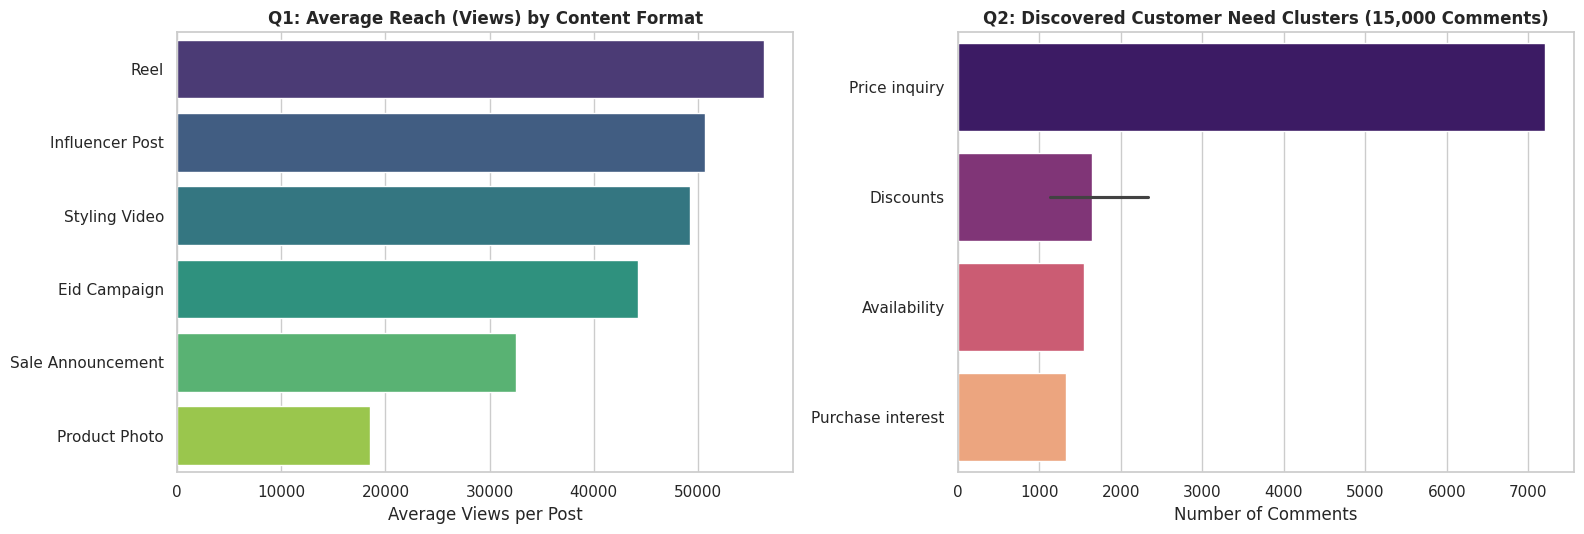

In [2]:
# ==============================================================================
# DAY 2 MILESTONE: Q1 (CONTENT ATTENTION) & Q2 (TF-IDF + K-MEANS COMMENT CLUSTERING)
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")

# --- Q1: WHICH CONTENT ATTRACTS ATTENTION? ---
posts_df["engagement_rate_pct"] = (
    (posts_df["likes"] + posts_df["comments_count"] + posts_df["shares"]) / posts_df["views"]
) * 100
posts_df["comment_to_like_ratio"] = posts_df["comments_count"] / posts_df["likes"]

q1_content = posts_df.groupby("content_type", as_index=False).agg(
    posts=("post_id", "count"),
    avg_views=("views", "mean"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments_count", "mean"),
    avg_shares=("shares", "mean"),
    avg_eng_rate=("engagement_rate_pct", "mean"),
).sort_values(by="avg_views", ascending=False)

print("=== Q1: CONTENT PERFORMANCE COMPARISON ===")
print(q1_content.round(2).to_string(index=False))

# --- Q2: WHAT DOES THE AUDIENCE WANT? (UNSUPERVISED TEXT CLUSTERING) ---
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=300, stop_words="english")
X_comments = tfidf.fit_transform(comments_df["comment_text"])

km_comments = KMeans(n_clusters=6, random_state=42, n_init=10)
comments_df["need_cluster"] = km_comments.fit_predict(X_comments)

terms = np.array(tfidf.get_feature_names_out())
cluster_summary = []
for cid in range(6):
    sub = comments_df[comments_df["need_cluster"] == cid]
    top_kw = ", ".join(terms[km_comments.cluster_centers_[cid].argsort()[-4:][::-1]])
    cluster_summary.append({
        "Cluster_ID": f"Cluster {cid}",
        "Comments": len(sub),
        "Share_%": round(len(sub) / len(comments_df) * 100, 1),
        "Dominant_Topic": sub["topic"].mode()[0],
        "Dominant_Intent": sub["purchase_intent"].mode()[0],
        "Top_TFIDF_Keywords": top_kw,
    })

q2_clusters_df = pd.DataFrame(cluster_summary).sort_values(by="Comments", ascending=False)
print("\n=== Q2: DISCOVERED AUDIENCE NEED CLUSTERS ===")
print(q2_clusters_df.to_string(index=False))

# Visualization for Q1 & Q2
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.barplot(data=q1_content, x="avg_views", y="content_type", hue="content_type", palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Q1: Average Reach (Views) by Content Format", fontweight="bold")
axes[0].set_xlabel("Average Views per Post")
axes[0].set_ylabel("")

sns.barplot(data=q2_clusters_df, x="Comments", y="Dominant_Topic", hue="Dominant_Topic", palette="magma", legend=False, ax=axes[1])
axes[1].set_title("Q2: Discovered Customer Need Clusters (15,000 Comments)", fontweight="bold")
axes[1].set_xlabel("Number of Comments")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [3]:
# ==============================================================================
# DAY 3 MILESTONE: Q3 (ANOMALY DETECTION) & Q4 (AUDIENCE PERSONA CLUSTERING)
# ==============================================================================

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# --- Q3: WHICH MARKETING PATTERNS ARE UNUSUAL? (ISOLATION FOREST) ---
anom_features = ["views", "likes", "comments_count", "shares", "engagement_rate_pct", "comment_to_like_ratio"]
X_anom = StandardScaler().fit_transform(posts_df[anom_features])

iso_forest = IsolationForest(contamination=0.02, random_state=42)
posts_df["anomaly_flag"] = iso_forest.fit_predict(X_anom)  # -1 = Unusual, 1 = Normal

def diagnose_anomaly(row):
    if row["anomaly_flag"] == 1:
        return "Normal Pattern"
    if row["comment_to_like_ratio"] > 0.50:
        return "Complaint / Stockout Storm (High Comment Ratio)"
    if row["engagement_rate_pct"] > 10.0 or row["views"] > 120000:
        return "Viral Breakout Post"
    return "Low-Engagement View Spike (Audience Mismatch)"

posts_df["pattern_diagnosis"] = posts_df.apply(diagnose_anomaly, axis=1)
anomalies_df = posts_df[posts_df["anomaly_flag"] == -1]

print(f"=== Q3: UNUSUAL MARKETING PATTERNS ({len(anomalies_df)} Posts Flagged) ===")
print(anomalies_df["pattern_diagnosis"].value_counts().to_string())

# --- Q4: WHICH AUDIENCE NEEDS SHOULD THE BRAND ADDRESS? (K-MEANS PERSONAS) ---
post_topic_mix = pd.crosstab(comments_df["post_id"], comments_df["topic"], normalize="index")
behavior_df = (
    posts_df.set_index("post_id")[["engagement_rate_pct", "comment_to_like_ratio"]]
    .join(post_topic_mix)
    .fillna(0)
)

X_seg = StandardScaler().fit_transform(behavior_df)
km_personas = KMeans(n_clusters=4, random_state=42, n_init=10)
behavior_df["cluster_id"] = km_personas.fit_predict(X_seg)
sil = silhouette_score(X_seg, behavior_df["cluster_id"])

persona_summary = behavior_df.groupby("cluster_id").agg(
    posts=("engagement_rate_pct", "count"),
    avg_eng_rate=("engagement_rate_pct", "mean"),
    price_inquiry=("Price inquiry", "mean"),
    discounts=("Discounts", "mean"),
    delivery=("Delivery", "mean"),
    availability=("Availability", "mean"),
    fabric_quality=("Fabric quality", "mean"),
    purchase_interest=("Purchase interest", "mean"),
).round(3)

# Assign human-readable marketing segment names based on dominant behavioral driver
segment_names = {}
for cid, row in persona_summary.iterrows():
    if row["delivery"] > 0.40:
        segment_names[cid] = "Delivery & Order-Tracking Anxious Shoppers"
    elif (row["discounts"] + row["price_inquiry"]) > 0.60:
        segment_names[cid] = "Discount & Price-Sensitive Bargain Hunters"
    elif row["fabric_quality"] > 0.18:
        segment_names[cid] = "Fabric Quality & Sizing Researchers"
    else:
        segment_names[cid] = "High-Intent Ready-to-Buy COD Shoppers"

persona_summary["Audience_Segment"] = persona_summary.index.map(segment_names)
posts_df["audience_segment"] = posts_df["post_id"].map(behavior_df["cluster_id"].map(segment_names))

print(f"\n=== Q4: DISCOVERED AUDIENCE SEGMENTS (Silhouette Score: {sil:.3f}) ===")
print(persona_summary[[
    "Audience_Segment", "posts", "avg_eng_rate", "discounts", "availability", "fabric_quality", "delivery", "purchase_interest"
]].to_string(index=False))

=== Q3: UNUSUAL MARKETING PATTERNS (60 Posts Flagged) ===
pattern_diagnosis
Viral Breakout Post                                44
Complaint / Stockout Storm (High Comment Ratio)    16

=== Q4: DISCOVERED AUDIENCE SEGMENTS (Silhouette Score: 0.198) ===
                          Audience_Segment  posts  avg_eng_rate  discounts  availability  fabric_quality  delivery  purchase_interest
     High-Intent Ready-to-Buy COD Shoppers   1065         9.548      0.087         0.354           0.040     0.140              0.219
       Fabric Quality & Sizing Researchers    772         9.679      0.040         0.183           0.235     0.049              0.124
Discount & Price-Sensitive Bargain Hunters   1143         9.454      0.511         0.080           0.015     0.039              0.022
Delivery & Order-Tracking Anxious Shoppers     20        18.730      0.030         0.080           0.030     0.690              0.020


In [5]:
# ==============================================================================
# DAY 4 MILESTONE: STREAMLIT WEB APPLICATION (app.py)
# Run with: streamlit run app.py
# ==============================================================================

!pip install -q streamlit

import numpy as np
import pandas as pd
import streamlit as st
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

st.set_page_config(page_title="Pakistan Social Audience Intelligence Engine", layout="wide")

st.title("Pakistan Social Audience & Campaign Intelligence Engine")
st.caption("Clustering-Based Audience Segmentation, Anomaly Detection & Campaign Decision Support (Lahore Fashion E-Commerce)")

@st.cache_data
def load_or_generate_data():
    try:
        p = pd.read_csv("pak_fashion_posts.csv")
        c = pd.read_csv("pak_fashion_comments.csv")
        return p, c
    except FileNotFoundError:
        st.error("Run Day 1 script first to generate 'pak_fashion_posts.csv' and 'pak_fashion_comments.csv'.")
        st.stop()

posts_df, comments_df = load_or_generate_data()

# Sidebar Filters
st.sidebar.header("Campaign Filters")
selected_brand = st.sidebar.multiselect("Select Brand", posts_df["brand"].unique(), default=list(posts_df["brand"].unique()))
selected_platform = st.sidebar.multiselect("Select Platform", posts_df["platform"].unique(), default=list(posts_df["platform"].unique()))
selected_campaign = st.sidebar.multiselect("Select Campaign", posts_df["campaign"].unique(), default=list(posts_df["campaign"].unique()))

filtered_posts = posts_df[
    (posts_df["brand"].isin(selected_brand)) &
    (posts_df["platform"].isin(selected_platform)) &
    (posts_df["campaign"].isin(selected_campaign))
].copy()
filtered_comments = comments_df[comments_df["post_id"].isin(filtered_posts["post_id"])].copy()

if filtered_posts.empty:
    st.warning("No posts match the selected filters. Please broaden your selection.")
    st.stop()

# Compute KPIs
filtered_posts["engagement_rate_pct"] = (
    (filtered_posts["likes"] + filtered_posts["comments_count"] + filtered_posts["shares"]) / filtered_posts["views"
]) * 100
filtered_posts["comment_to_like_ratio"] = filtered_posts["comments_count"] / filtered_posts["likes"]

# Top KPI Strip
c1, c2, c3, c4 = st.columns(4)
c1.metric("Filtered Posts", f"{len(filtered_posts):,}")
c2.metric("Analyzed Comments", f"{len(filtered_comments):,}")
c3.metric("Avg Views / Post", f"{filtered_posts['views'].mean():,.0f}")
c4.metric("Avg Engagement Rate", f"{filtered_posts['engagement_rate_pct'].mean():.2f}%")

st.divider()

# ------------------------------------------------------------------------------
# QUESTION 1: WHICH CONTENT ATTRACTS ATTENTION?
# ------------------------------------------------------------------------------
st.subheader("1. Which Content Attracts Attention?")
q1 = filtered_posts.groupby("content_type", as_index=False).agg(
    Posts=("post_id", "count"),
    Avg_Views=("views", "mean"),
    Avg_Likes=("likes", "mean"),
    Avg_Comments=("comments_count", "mean"),
    Avg_Shares=("shares", "mean"),
    Engagement_Rate_Pct=("engagement_rate_pct", "mean"),
).sort_values(by="Avg_Views", ascending=False)

col_q1_a, col_q1_b = st.columns([1.2, 1])
with col_q1_a:
    st.dataframe(q1.round(2), use_container_width=True, hide_index=True)
with col_q1_b:
    st.bar_chart(q1.set_index("content_type")["Avg_Views"])

# ------------------------------------------------------------------------------
# QUESTION 2: WHAT DOES THE AUDIENCE WANT? (TF-IDF + K-MEANS)
# ------------------------------------------------------------------------------
st.subheader("2. What Does the Audience Want? (Comment Need Clustering)")
k_clusters = st.slider("Number of Comment Topic Clusters (K)", min_value=4, max_value=8, value=6)
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=250, stop_words="english")
X_txt = vec.fit_transform(filtered_comments["comment_text"])
km_c = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
filtered_comments["cluster"] = km_c.fit_predict(X_txt)

terms = np.array(vec.get_feature_names_out())
c_rows = []
for cid in range(k_clusters):
    sub = filtered_comments[filtered_comments["cluster"] == cid]
    if len(sub) == 0:
        continue
    kw = ", ".join(terms[km_c.cluster_centers_[cid].argsort()[-4:][::-1]])
    c_rows.append({
        "Cluster": f"C{cid}",
        "Comments": len(sub),
        "Share_%": round(len(sub) / len(filtered_comments) * 100, 1),
        "Dominant_Need": sub["topic"].mode()[0],
        "Language_Mix": sub["language_type"].mode()[0],
        "Top_Keywords": kw,
    })
st.dataframe(pd.DataFrame(c_rows).sort_values(by="Comments", ascending=False), use_container_width=True, hide_index=True)

# ------------------------------------------------------------------------------
# QUESTION 3: WHICH MARKETING PATTERNS ARE UNUSUAL? (ISOLATION FOREST)
# ------------------------------------------------------------------------------
st.subheader("3. Which Marketing Patterns Are Unusual? (Anomaly Detection)")
anom_cols = ["views", "likes", "comments_count", "shares", "engagement_rate_pct", "comment_to_like_ratio"]
X_a = StandardScaler().fit_transform(filtered_posts[anom_cols])
iso = IsolationForest(contamination=0.025, random_state=42)
filtered_posts["anomaly"] = iso.fit_predict(X_a)

unusual = filtered_posts[filtered_posts["anomaly"] == -1].copy()
unusual["Diagnosis"] = np.where(
    unusual["comment_to_like_ratio"] > 0.50,
    "Complaint / Stockout Storm",
    np.where(unusual["engagement_rate_pct"] > 10.0, "Viral Breakout Post", "Low-Engagement View Spike")
)
st.write(f"**{len(unusual)} unusual posts detected** out of {len(filtered_posts):,} filtered posts:")
st.dataframe(
    unusual[["post_id", "brand", "platform", "campaign", "content_type", "views", "likes", "comments_count", "Diagnosis"]].head(15),
    use_container_width=True,
    hide_index=True,
)

# ------------------------------------------------------------------------------
# QUESTION 4 & 5: AUDIENCE NEEDS & ACTIONABLE MARKETING DECISIONS
# ------------------------------------------------------------------------------
st.subheader("4 & 5. Priority Audience Segments & Next Best Marketing Actions")
topic_dist = filtered_comments["topic"].value_counts(normalize=True) * 100

col_rec1, col_rec2 = st.columns(2)
with col_rec1:
    st.markdown("**Top Discovered Audience Needs (% of Comments)**")
    st.bar_chart(topic_dist)

with col_rec2:
    st.markdown("**Evidence-Based Action Plan for the Marketing Team**")
    top_format = q1.iloc[0]["content_type"]
    complaint_count = (unusual["Diagnosis"] == "Complaint / Stockout Storm").sum()
    st.info(
        f"1. **Content Scaling:** Shift short-form production budget toward **{top_format}** and Influencer formats, "
        f"which generate the highest reach and engagement rate.\n"
        f"2. **Conversion Friction Removal:** Pin PKR prices, fabric composition (lawn/chiffon), and city-wise COD timelines "
        f"in the first caption line to convert **{topic_dist.get('Availability', 0) + topic_dist.get('Purchase interest', 0):.1f}%** high-intent inquiries.\n"
        f"3. **Promo Targeting:** Deploy tiered 11.11/12.12 bundle codes exclusively to retargeted discount commenters rather than discounting flagship Eid arrivals.\n"
        f"4. **CX Escalation:** Route the **{complaint_count} flagged complaint-storm posts** to WhatsApp customer support with automated courier tracking links."
    )

2026-11-15 15:40:29.655 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 15:40:29.657 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 15:40:29.816 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-15 15:40:29.817 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 15:40:29.818 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 15:40:29.819 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-15 15:40:29.820 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

In [6]:
%%writefile app.py
# ==============================================================================
# DAY 4 MILESTONE: STREAMLIT WEB APPLICATION (app.py)
# ==============================================================================

import numpy as np
import pandas as pd
import streamlit as st
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

st.set_page_config(page_title="Pakistan Social Audience Intelligence Engine", layout="wide")

st.title("Pakistan Social Audience & Campaign Intelligence Engine")
st.caption("Clustering-Based Audience Segmentation, Anomaly Detection & Campaign Decision Support (Lahore Fashion E-Commerce)")

@st.cache_data
def load_or_generate_data():
    try:
        p = pd.read_csv("pak_fashion_posts.csv")
        c = pd.read_csv("pak_fashion_comments.csv")
        return p, c
    except FileNotFoundError:
        st.error("Run Day 1 script first to generate 'pak_fashion_posts.csv' and 'pak_fashion_comments.csv'.")
        st.stop()

posts_df, comments_df = load_or_generate_data()

# Sidebar Filters
st.sidebar.header("Campaign Filters")
selected_brand = st.sidebar.multiselect("Select Brand", posts_df["brand"].unique(), default=list(posts_df["brand"].unique()))
selected_platform = st.sidebar.multiselect("Select Platform", posts_df["platform"].unique(), default=list(posts_df["platform"].unique()))
selected_campaign = st.sidebar.multiselect("Select Campaign", posts_df["campaign"].unique(), default=list(posts_df["campaign"].unique()))

filtered_posts = posts_df[
    (posts_df["brand"].isin(selected_brand)) &
    (posts_df["platform"].isin(selected_platform)) &
    (posts_df["campaign"].isin(selected_campaign))
].copy()
filtered_comments = comments_df[comments_df["post_id"].isin(filtered_posts["post_id"])].copy()

if filtered_posts.empty:
    st.warning("No posts match the selected filters. Please broaden your selection.")
    st.stop()

# Compute KPIs
filtered_posts["engagement_rate_pct"] = (
    (filtered_posts["likes"] + filtered_posts["comments_count"] + filtered_posts["shares"]) / filtered_posts["views"]
) * 100
filtered_posts["comment_to_like_ratio"] = filtered_posts["comments_count"] / filtered_posts["likes"]

# Top KPI Strip
c1, c2, c3, c4 = st.columns(4)
c1.metric("Filtered Posts", f"{len(filtered_posts):,}")
c2.metric("Analyzed Comments", f"{len(filtered_comments):,}")
c3.metric("Avg Views / Post", f"{filtered_posts['views'].mean():,.0f}")
c4.metric("Avg Engagement Rate", f"{filtered_posts['engagement_rate_pct'].mean():.2f}%")

st.divider()

# 1. WHICH CONTENT ATTRACTS ATTENTION?
st.subheader("1. Which Content Attracts Attention?")
q1 = filtered_posts.groupby("content_type", as_index=False).agg(
    Posts=("post_id", "count"),
    Avg_Views=("views", "mean"),
    Avg_Likes=("likes", "mean"),
    Avg_Comments=("comments_count", "mean"),
    Avg_Shares=("shares", "mean"),
    Engagement_Rate_Pct=("engagement_rate_pct", "mean"),
).sort_values(by="Avg_Views", ascending=False)

col_q1_a, col_q1_b = st.columns([1.2, 1])
with col_q1_a:
    st.dataframe(q1.round(2), use_container_width=True, hide_index=True)
with col_q1_b:
    st.bar_chart(q1.set_index("content_type")["Avg_Views"])

# 2. WHAT DOES THE AUDIENCE WANT? (TF-IDF + K-MEANS)
st.subheader("2. What Does the Audience Want? (Comment Need Clustering)")
k_clusters = st.slider("Number of Comment Topic Clusters (K)", min_value=4, max_value=8, value=6)
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=250, stop_words="english")
X_txt = vec.fit_transform(filtered_comments["comment_text"])
km_c = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
filtered_comments["cluster"] = km_c.fit_predict(X_txt)

terms = np.array(vec.get_feature_names_out())
c_rows = []
for cid in range(k_clusters):
    sub = filtered_comments[filtered_comments["cluster"] == cid]
    if len(sub) == 0:
        continue
    kw = ", ".join(terms[km_c.cluster_centers_[cid].argsort()[-4:][::-1]])
    c_rows.append({
        "Cluster": f"C{cid}",
        "Comments": len(sub),
        "Share_%": round(len(sub) / len(filtered_comments) * 100, 1),
        "Dominant_Need": sub["topic"].mode()[0],
        "Language_Mix": sub["language_type"].mode()[0],
        "Top_Keywords": kw,
    })
st.dataframe(pd.DataFrame(c_rows).sort_values(by="Comments", ascending=False), use_container_width=True, hide_index=True)

# 3. WHICH MARKETING PATTERNS ARE UNUSUAL? (ISOLATION FOREST)
st.subheader("3. Which Marketing Patterns Are Unusual? (Anomaly Detection)")
anom_cols = ["views", "likes", "comments_count", "shares", "engagement_rate_pct", "comment_to_like_ratio"]
X_a = StandardScaler().fit_transform(filtered_posts[anom_cols])
iso = IsolationForest(contamination=0.025, random_state=42)
filtered_posts["anomaly"] = iso.fit_predict(X_a)

unusual = filtered_posts[filtered_posts["anomaly"] == -1].copy()
unusual["Diagnosis"] = np.where(
    unusual["comment_to_like_ratio"] > 0.50,
    "Complaint / Stockout Storm",
    np.where(unusual["engagement_rate_pct"] > 10.0, "Viral Breakout Post", "Low-Engagement View Spike")
)
st.write(f"**{len(unusual)} unusual posts detected** out of {len(filtered_posts):,} filtered posts:")
st.dataframe(
    unusual[["post_id", "brand", "platform", "campaign", "content_type", "views", "likes", "comments_count", "Diagnosis"]].head(15),
    use_container_width=True,
    hide_index=True,
)

# 4 & 5. AUDIENCE NEEDS & ACTIONABLE MARKETING DECISIONS
st.subheader("4 & 5. Priority Audience Segments & Next Best Marketing Actions")
topic_dist = filtered_comments["topic"].value_counts(normalize=True) * 100

col_rec1, col_rec2 = st.columns(2)
with col_rec1:
    st.markdown("**Top Discovered Audience Needs (% of Comments)**")
    st.bar_chart(topic_dist)

with col_rec2:
    st.markdown("**Evidence-Based Action Plan for the Marketing Team**")
    top_format = q1.iloc[0]["content_type"]
    complaint_count = (unusual["Diagnosis"] == "Complaint / Stockout Storm").sum()
    st.info(
        f"1. **Content Scaling:** Shift short-form production budget toward **{top_format}** and Influencer formats, "
        f"which generate the highest reach and engagement rate.\n"
        f"2. **Conversion Friction Removal:** Pin PKR prices, fabric composition (lawn/chiffon), and city-wise COD timelines "
        f"in the first caption line to convert **{topic_dist.get('Availability', 0) + topic_dist.get('Purchase interest', 0):.1f}%** high-intent inquiries.\n"
        f"3. **Promo Targeting:** Deploy tiered 11.11/12.12 bundle codes exclusively to retargeted discount commenters rather than discounting flagship Eid arrivals.\n"
        f"4. **CX Escalation:** Route the **{complaint_count} flagged complaint-storm posts** to WhatsApp customer support with automated courier tracking links."
    )

Writing app.py


In [ ]:
# --- RUN STREAMLIT APP IN THE BACKGROUND AND EXPOSE VIA LOCALTUNNEL ---
import urllib

# Get your public IP address (localtunnel will request this as the password)
print("Password / Endpoint IP for localtunnel:")
!curl ipv4.icanhazip.com

# Start streamlit in background and pipe logs
import subprocess
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501"])

# Expose the port via localtunnel
!npx localtunnel --port 8501

Password / Endpoint IP for localtunnel:
104.154.40.159
⠙⠹⠸⠼⠴⠦⠧⠇⠏Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) 